<a href="https://colab.research.google.com/github/moiz-shahid/Deep-Learning-Tutorials/blob/main/Tutorial-07-Feature-Extraction-Fine-Tuning/DL_Tutorial_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import os
import torch
import torchvision
import matplotlib.pyplot as plt

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

Using device: cuda


In [2]:
import urllib.request
import zipfile

url = "https://download.pytorch.org/tutorial/hymenoptera_data.zip"

zip_path = "/content/hymenoptera_data.zip"

urllib.request.urlretrieve(url, zip_path)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall("/content")

print("Dataset downloaded and extracted successfully.")

Dataset downloaded and extracted successfully.


In [3]:
data_transforms = {
    "train": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ]),

    "val": transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(
            [0.485, 0.456, 0.406],
            [0.229, 0.224, 0.225]
        )
    ])
}

In [4]:
data_dir = "/content/hymenoptera_data"

image_datasets = {
    split: datasets.ImageFolder(
        os.path.join(data_dir, split),
        data_transforms[split]
    )
    for split in ["train", "val"]
}

dataloaders = {
    split: DataLoader(
        image_datasets[split],
        batch_size=16,
        shuffle=(split == "train")
    )
    for split in ["train", "val"]
}

class_names = image_datasets["train"].classes

print("Classes:", class_names)
print("Training images:", len(image_datasets["train"]))
print("Validation images:", len(image_datasets["val"]))

Classes: ['ants', 'bees']
Training images: 244
Validation images: 153


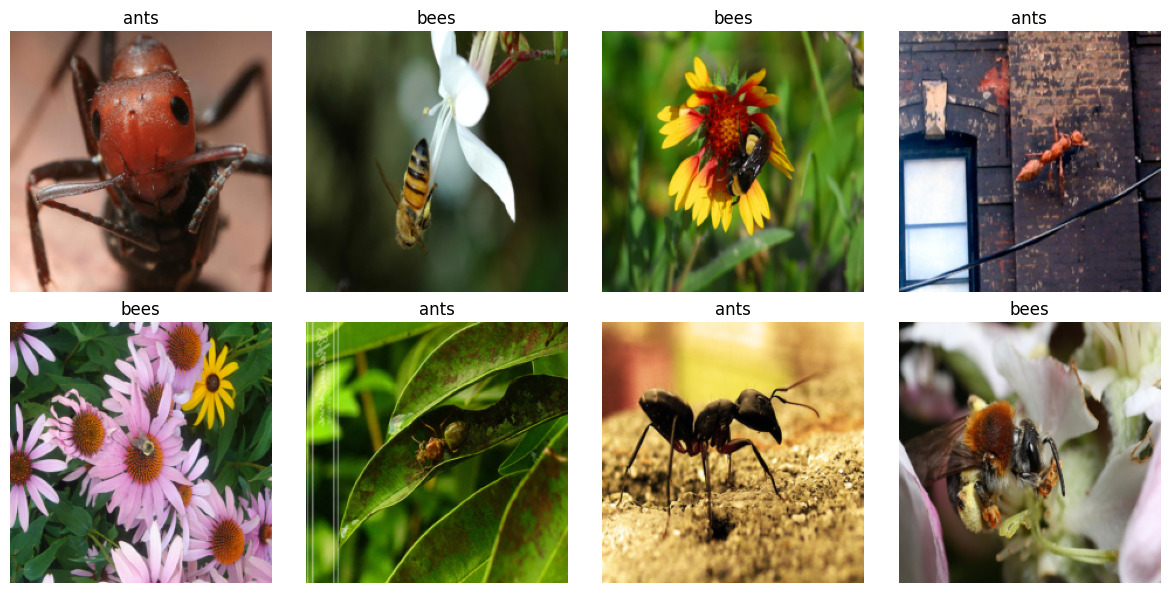

In [5]:
images, labels = next(iter(dataloaders["train"]))

plt.figure(figsize=(12, 6))

for i in range(8):

    image = images[i].permute(1, 2, 0).numpy()

    mean = [0.485, 0.456, 0.406]
    std = [0.229, 0.224, 0.225]

    image = image * std + mean
    image = image.clip(0, 1)

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(class_names[labels[i].item()])
    plt.axis("off")

plt.tight_layout()
plt.show()

# Experiment 1 — VGG16 Feature Extraction

In this experiment, pretrained VGG16 is used as a frozen feature extractor. Its original classifier is replaced with a new binary classifier for ants and bees. Only the new classification layer is trained.

In [6]:
import torch.nn as nn
import torch.optim as optim
from torchvision.models import VGG16_Weights

# Load pretrained VGG16
vgg16 = models.vgg16(
    weights=VGG16_Weights.DEFAULT
)

# Freeze all pretrained parameters
for param in vgg16.parameters():
    param.requires_grad = False

# Replace original classifier with a smaller classifier
vgg16.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 256),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(256, 2)
)

vgg16 = vgg16.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    vgg16.classifier.parameters(),
    lr=0.001
)

print("VGG16 feature extraction model ready.")

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:06<00:00, 85.9MB/s]


VGG16 feature extraction model ready.


In [9]:
import copy
import time

def train_model(model, dataloaders, criterion, optimizer,
                num_epochs=10, patience=3):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_acc = 0.0
    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())

    wait = 0
    start_time = time.time()

    for epoch in range(num_epochs):

        print(f"\nEpoch {epoch+1}/{num_epochs}")

        for phase in ["train", "val"]:

            if phase == "train":
                model.train()
            else:
                model.eval()

            running_loss = 0.0
            running_correct = 0
            total = 0

            for images, labels in dataloaders[phase]:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):

                    outputs = model(images)

                    loss = criterion(outputs, labels)

                    predictions = outputs.argmax(dim=1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * labels.size(0)
                running_correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

            epoch_loss = running_loss / total
            epoch_acc = 100 * running_correct / total

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            print(
                f"{phase.upper()} | "
                f"Loss: {epoch_loss:.4f} | "
                f"Accuracy: {epoch_acc:.2f}%"
            )

            if phase == "val":

                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_acc = epoch_acc
                    best_weights = copy.deepcopy(model.state_dict())
                    wait = 0
                else:
                    wait += 1

        if wait >= patience:
            print("\nEarly Stopping triggered.")
            break

    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    print("\nTraining completed.")
    print("Best Validation Accuracy:", round(best_acc, 2), "%")
    print("Best Validation Loss:", round(best_loss, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    return model, history, training_time

In [10]:
vgg16, vgg_history, vgg_time = train_model(
    model=vgg16,
    dataloaders=dataloaders,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=10,
    patience=3
)


Epoch 1/10
TRAIN | Loss: 0.5030 | Accuracy: 83.20%
VAL | Loss: 0.8835 | Accuracy: 92.16%

Epoch 2/10
TRAIN | Loss: 0.2841 | Accuracy: 94.26%
VAL | Loss: 0.8610 | Accuracy: 90.85%

Epoch 3/10
TRAIN | Loss: 0.2590 | Accuracy: 96.72%
VAL | Loss: 0.8883 | Accuracy: 91.50%

Epoch 4/10
TRAIN | Loss: 0.1826 | Accuracy: 97.95%
VAL | Loss: 0.8417 | Accuracy: 94.12%

Epoch 5/10
TRAIN | Loss: 0.1127 | Accuracy: 97.95%
VAL | Loss: 0.8496 | Accuracy: 94.77%

Epoch 6/10
TRAIN | Loss: 0.0141 | Accuracy: 99.59%
VAL | Loss: 0.7884 | Accuracy: 94.12%

Epoch 7/10
TRAIN | Loss: 0.0273 | Accuracy: 98.36%
VAL | Loss: 1.0455 | Accuracy: 92.16%

Epoch 8/10
TRAIN | Loss: 0.0434 | Accuracy: 98.36%
VAL | Loss: 0.9819 | Accuracy: 91.50%

Epoch 9/10
TRAIN | Loss: 0.1351 | Accuracy: 97.13%
VAL | Loss: 1.1229 | Accuracy: 92.16%

Early Stopping triggered.

Training completed.
Best Validation Accuracy: 94.12 %
Best Validation Loss: 0.7884
Training Time: 39.6 seconds


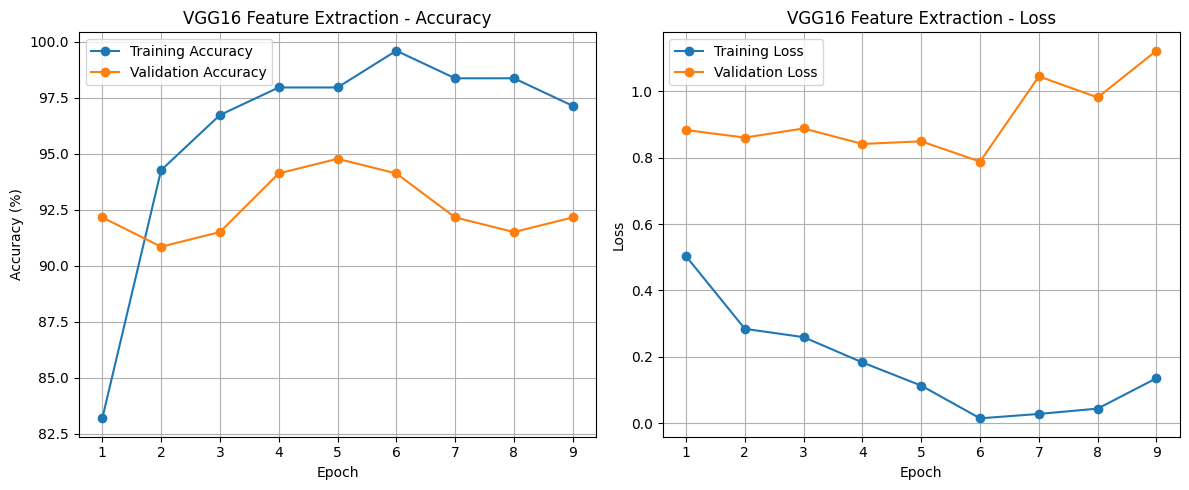

In [11]:
epochs_range = range(1, len(vgg_history["train_acc"]) + 1)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    vgg_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    vgg_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("VGG16 Feature Extraction - Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    vgg_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    vgg_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Feature Extraction - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [12]:
import os

save_dir = "/content/tutorial7_checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "classifier_state_dict": vgg16.classifier.state_dict(),
    "history": vgg_history,
    "training_time": vgg_time
}, os.path.join(save_dir, "vgg16_feature_extraction.pth"))

print("VGG16 feature extraction checkpoint saved.")

VGG16 feature extraction checkpoint saved.


In [13]:
print("VGG16 Feature Extraction Results")
print("--------------------------------")

print(
    "Best Validation Accuracy:",
    round(max(vgg_history["val_acc"]), 2),
    "%"
)

print(
    "Lowest Validation Loss:",
    round(min(vgg_history["val_loss"]), 4)
)

print(
    "Training Time:",
    round(vgg_time, 2),
    "seconds"
)

VGG16 Feature Extraction Results
--------------------------------
Best Validation Accuracy: 94.77 %
Lowest Validation Loss: 0.7884
Training Time: 39.6 seconds


In [14]:
# Experiment 1B - Improved VGG16 Feature Extraction

from torchvision import models
from torchvision.models import VGG16_Weights
import torch.nn as nn
import torch.optim as optim

# Load a fresh pretrained VGG16
vgg16_improved = models.vgg16(
    weights=VGG16_Weights.DEFAULT
)

# Freeze pretrained feature extractor
for param in vgg16_improved.parameters():
    param.requires_grad = False

# Smaller classification head
vgg16_improved.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 64),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(64, 2)
)

vgg16_improved = vgg16_improved.to(device)

# Loss function
criterion_improved = nn.CrossEntropyLoss()

# New optimizer for the improved classifier
optimizer_improved = optim.Adam(
    vgg16_improved.classifier.parameters(),
    lr=0.0001,
    weight_decay=0.001
)

print("Improved VGG16 model ready.")

Improved VGG16 model ready.


In [15]:
vgg16_improved, vgg_improved_history, vgg_improved_time = train_model(
    model=vgg16_improved,
    dataloaders=dataloaders,
    criterion=criterion_improved,
    optimizer=optimizer_improved,
    num_epochs=10,
    patience=3
)


Epoch 1/10
TRAIN | Loss: 0.5955 | Accuracy: 68.85%
VAL | Loss: 0.3048 | Accuracy: 93.46%

Epoch 2/10
TRAIN | Loss: 0.2045 | Accuracy: 93.44%
VAL | Loss: 0.2423 | Accuracy: 91.50%

Epoch 3/10
TRAIN | Loss: 0.1295 | Accuracy: 94.67%
VAL | Loss: 0.2206 | Accuracy: 94.77%

Epoch 4/10
TRAIN | Loss: 0.0717 | Accuracy: 98.77%
VAL | Loss: 0.2321 | Accuracy: 92.81%

Epoch 5/10
TRAIN | Loss: 0.0407 | Accuracy: 99.59%
VAL | Loss: 0.2271 | Accuracy: 94.12%

Epoch 6/10
TRAIN | Loss: 0.0473 | Accuracy: 98.77%
VAL | Loss: 0.2274 | Accuracy: 94.12%

Early Stopping triggered.

Training completed.
Best Validation Accuracy: 94.77 %
Best Validation Loss: 0.2206
Training Time: 25.17 seconds


In [16]:
print("Original VGG16:")
print("Best Validation Accuracy:",
      round(max(vgg_history["val_acc"]), 2), "%")
print("Lowest Validation Loss:",
      round(min(vgg_history["val_loss"]), 4))

print("\nImproved VGG16:")
print("Best Validation Accuracy:",
      round(max(vgg_improved_history["val_acc"]), 2), "%")
print("Lowest Validation Loss:",
      round(min(vgg_improved_history["val_loss"]), 4))

Original VGG16:
Best Validation Accuracy: 94.77 %
Lowest Validation Loss: 0.7884

Improved VGG16:
Best Validation Accuracy: 94.77 %
Lowest Validation Loss: 0.2206


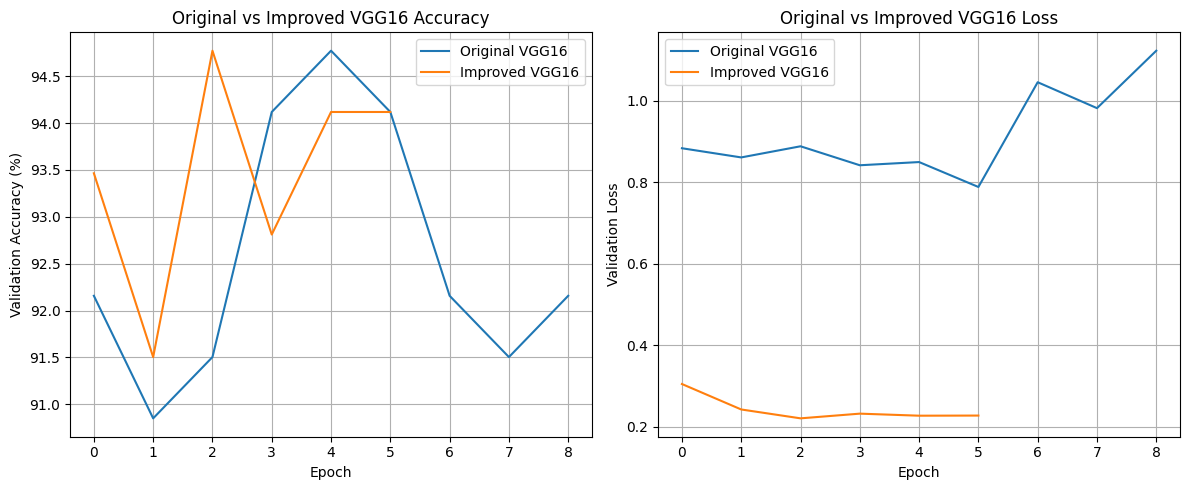

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    vgg_history["val_acc"],
    label="Original VGG16"
)

plt.plot(
    vgg_improved_history["val_acc"],
    label="Improved VGG16"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("Original vs Improved VGG16 Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    vgg_history["val_loss"],
    label="Original VGG16"
)

plt.plot(
    vgg_improved_history["val_loss"],
    label="Improved VGG16"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("Original vs Improved VGG16 Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

## Experiment 1B: Improving VGG16 Feature Extraction

To reduce the overfitting observed in the original VGG16 feature-extraction experiment, the classifier architecture and training settings were modified.

The number of hidden neurons was reduced from 256 to 64, the learning rate was decreased from 0.001 to 0.0001, and weight decay of 0.001 was introduced.

### Results

| Metric | Original VGG16 | Improved VGG16 |
|---|---:|---:|
| Best Validation Accuracy | 94.77% | 94.77% |
| Lowest Validation Loss | 0.7884 | 0.2206 |
| Training Time | 39.60 s | 25.17 s |
| Epochs Completed | 9 | 6 |

### Observations

Both models achieved the same maximum validation accuracy of 94.77%. However, the improved VGG16 model achieved a substantially lower validation loss, decreasing from 0.7884 to 0.2206.

The reduced validation loss indicates that the improved model assigned better probabilities to the correct classes, despite achieving the same classification accuracy.

The smaller classifier also required less training time in this experiment.

Although training accuracy still approached 100%, the lower validation loss and earlier stopping suggest improved generalization compared with the original model.

### Conclusion

Reducing the classifier size, lowering the learning rate, and introducing weight decay helped improve VGG16 feature extraction.

The modified model maintained **94.77% validation accuracy** while reducing validation loss by approximately **72%**.

Therefore, the improved VGG16 model achieved better validation-loss performance, although some overfitting remained.

# Experiment 2 — ResNet50 Fine-Tuning

In this experiment, a pretrained ResNet50 model is adapted to classify ants and bees. Earlier pretrained layers are frozen, while the final residual block and a new two-class classification layer are trained.

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.models import ResNet50_Weights

# Load pretrained ResNet50
resnet50_ft = models.resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Freeze all pretrained parameters
for param in resnet50_ft.parameters():
    param.requires_grad = False

# Unfreeze the last residual block
for param in resnet50_ft.layer4.parameters():
    param.requires_grad = True

# Replace original classifier
resnet50_ft.fc = nn.Linear(
    resnet50_ft.fc.in_features,
    2
)

resnet50_ft = resnet50_ft.to(device)

print("ResNet50 Fine-Tuning Model Ready")
print("Final Layer:", resnet50_ft.fc)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 128MB/s]


ResNet50 Fine-Tuning Model Ready
Final Layer: Linear(in_features=2048, out_features=2, bias=True)


In [19]:
total_params = sum(
    p.numel() for p in resnet50_ft.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet50_ft.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", total_params - trainable_params)

Total Parameters: 23512130
Trainable Parameters: 14968834
Frozen Parameters: 8543296


In [20]:
criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam([
    {
        "params": resnet50_ft.layer4.parameters(),
        "lr": 0.00001
    },
    {
        "params": resnet50_ft.fc.parameters(),
        "lr": 0.0001
    }
], weight_decay=0.0001)

print("Optimizer Ready")

Optimizer Ready


In [21]:
import copy
import time

def train_model(model, dataloaders, criterion, optimizer,
                num_epochs=10, patience=3):

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": []
    }

    best_loss = float("inf")
    best_weights = copy.deepcopy(model.state_dict())
    best_epoch = 0
    best_acc = 0.0

    wait = 0
    start_time = time.time()

    for epoch in range(num_epochs):

        print(f"\nEpoch {epoch + 1}/{num_epochs}")

        for phase in ["train", "val"]:

            if phase == "train":
                model.train()

                # Keep BatchNorm running statistics fixed
                for module in model.modules():
                    if isinstance(module, nn.modules.batchnorm._BatchNorm):
                        module.eval()

            else:
                model.eval()

            running_loss = 0.0
            running_correct = 0
            total = 0

            for images, labels in dataloaders[phase]:

                images = images.to(device)
                labels = labels.to(device)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):

                    outputs = model(images)
                    loss = criterion(outputs, labels)
                    predictions = outputs.argmax(dim=1)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * labels.size(0)
                running_correct += (
                    predictions == labels
                ).sum().item()

                total += labels.size(0)

            epoch_loss = running_loss / total
            epoch_acc = 100 * running_correct / total

            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            print(
                f"{phase.upper()} | "
                f"Loss: {epoch_loss:.4f} | "
                f"Accuracy: {epoch_acc:.2f}%"
            )

            if phase == "val":

                if epoch_loss < best_loss:
                    best_loss = epoch_loss
                    best_acc = epoch_acc
                    best_epoch = epoch + 1
                    best_weights = copy.deepcopy(
                        model.state_dict()
                    )
                    wait = 0
                else:
                    wait += 1

        if wait >= patience:
            print("\nEarly Stopping triggered.")
            break

    model.load_state_dict(best_weights)

    training_time = time.time() - start_time

    print("\nTraining completed.")
    print("Best Epoch:", best_epoch)
    print("Validation Accuracy at Best Epoch:", round(best_acc, 2), "%")
    print("Best Validation Loss:", round(best_loss, 4))
    print("Training Time:", round(training_time, 2), "seconds")

    return model, history, training_time

In [22]:
resnet50_ft, resnet_ft_history, resnet_ft_time = train_model(
    model=resnet50_ft,
    dataloaders=dataloaders,
    criterion=criterion_resnet,
    optimizer=optimizer_resnet,
    num_epochs=10,
    patience=3
)


Epoch 1/10
TRAIN | Loss: 0.6671 | Accuracy: 64.75%
VAL | Loss: 0.6332 | Accuracy: 78.43%

Epoch 2/10
TRAIN | Loss: 0.5743 | Accuracy: 95.08%
VAL | Loss: 0.5390 | Accuracy: 92.16%

Epoch 3/10
TRAIN | Loss: 0.4235 | Accuracy: 97.54%
VAL | Loss: 0.3541 | Accuracy: 93.46%

Epoch 4/10
TRAIN | Loss: 0.1890 | Accuracy: 97.95%
VAL | Loss: 0.1568 | Accuracy: 95.42%

Epoch 5/10
TRAIN | Loss: 0.0591 | Accuracy: 99.18%
VAL | Loss: 0.1086 | Accuracy: 95.42%

Epoch 6/10
TRAIN | Loss: 0.0176 | Accuracy: 99.59%
VAL | Loss: 0.0988 | Accuracy: 96.08%

Epoch 7/10
TRAIN | Loss: 0.0072 | Accuracy: 100.00%
VAL | Loss: 0.1105 | Accuracy: 95.42%

Epoch 8/10
TRAIN | Loss: 0.0033 | Accuracy: 100.00%
VAL | Loss: 0.1063 | Accuracy: 96.08%

Epoch 9/10
TRAIN | Loss: 0.0022 | Accuracy: 100.00%
VAL | Loss: 0.1058 | Accuracy: 96.08%

Early Stopping triggered.

Training completed.
Best Epoch: 6
Validation Accuracy at Best Epoch: 96.08 %
Best Validation Loss: 0.0988
Training Time: 35.44 seconds


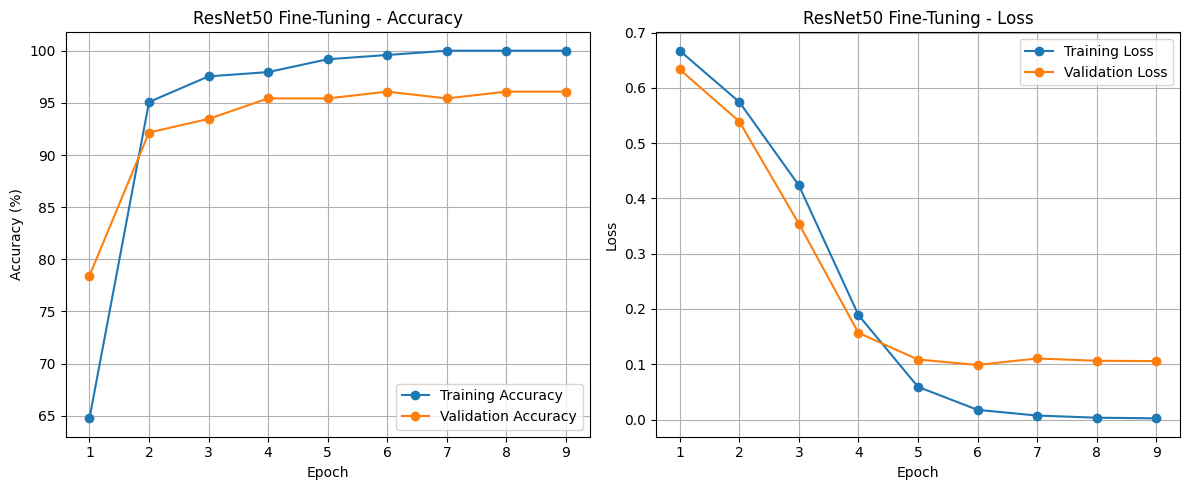

In [23]:
epochs_range = range(
    1,
    len(resnet_ft_history["train_acc"]) + 1
)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    resnet_ft_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    resnet_ft_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 Fine-Tuning - Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    resnet_ft_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    resnet_ft_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Fine-Tuning - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [24]:
print("VGG16 Feature Extraction")
print("Accuracy:", round(max(vgg_history["val_acc"]), 2), "%")
print("Loss:", round(min(vgg_history["val_loss"]), 4))

print("\nImproved VGG16 Feature Extraction")
print("Accuracy:", round(max(vgg_improved_history["val_acc"]), 2), "%")
print("Loss:", round(min(vgg_improved_history["val_loss"]), 4))

print("\nResNet50 Fine-Tuning")
print("Accuracy:", round(max(resnet_ft_history["val_acc"]), 2), "%")
print("Loss:", round(min(resnet_ft_history["val_loss"]), 4))

VGG16 Feature Extraction
Accuracy: 94.77 %
Loss: 0.7884

Improved VGG16 Feature Extraction
Accuracy: 94.77 %
Loss: 0.2206

ResNet50 Fine-Tuning
Accuracy: 96.08 %
Loss: 0.0988


In [25]:
import os

save_dir = "/content/tutorial7_checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "layer4_state_dict": resnet50_ft.layer4.state_dict(),
    "fc_state_dict": resnet50_ft.fc.state_dict(),
    "history": resnet_ft_history,
    "training_time": resnet_ft_time
}, os.path.join(save_dir, "resnet50_finetuning.pth"))

print("ResNet50 fine-tuning checkpoint saved.")

ResNet50 fine-tuning checkpoint saved.


# Experiment 3 — ResNet50 Feature Extraction

In this experiment, pretrained ResNet50 is used as a fixed feature extractor. All pretrained layers are frozen, and only a new fully connected layer is trained to classify ants and bees.

The results will be compared with ResNet50 fine-tuning and VGG16 feature extraction.

In [26]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.models import ResNet50_Weights

# Load pretrained ResNet50
resnet50_fe = models.resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Freeze all pretrained layers
for param in resnet50_fe.parameters():
    param.requires_grad = False

# Replace the original 1000-class classifier
# with a new 2-class classifier
resnet50_fe.fc = nn.Linear(
    resnet50_fe.fc.in_features,
    2
)

# Move model to GPU/CPU
resnet50_fe = resnet50_fe.to(device)

print("ResNet50 Feature Extraction Model Ready")
print(resnet50_fe.fc)

ResNet50 Feature Extraction Model Ready
Linear(in_features=2048, out_features=2, bias=True)


In [27]:
total_params = sum(
    p.numel() for p in resnet50_fe.parameters()
)

trainable_params = sum(
    p.numel()
    for p in resnet50_fe.parameters()
    if p.requires_grad
)

frozen_params = total_params - trainable_params

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", frozen_params)

Total Parameters: 23512130
Trainable Parameters: 4098
Frozen Parameters: 23508032


In [28]:
criterion_resnet_fe = nn.CrossEntropyLoss()

optimizer_resnet_fe = optim.Adam(
    resnet50_fe.fc.parameters(),
    lr=0.0001
)

print("Optimizer Ready")

Optimizer Ready


In [29]:
resnet50_fe, resnet_fe_history, resnet_fe_time = train_model(
    model=resnet50_fe,
    dataloaders=dataloaders,
    criterion=criterion_resnet_fe,
    optimizer=optimizer_resnet_fe,
    num_epochs=10,
    patience=3
)


Epoch 1/10
TRAIN | Loss: 0.6317 | Accuracy: 83.61%
VAL | Loss: 0.6178 | Accuracy: 86.27%

Epoch 2/10
TRAIN | Loss: 0.5990 | Accuracy: 90.57%
VAL | Loss: 0.5926 | Accuracy: 91.50%

Epoch 3/10
TRAIN | Loss: 0.5718 | Accuracy: 93.85%
VAL | Loss: 0.5699 | Accuracy: 92.16%

Epoch 4/10
TRAIN | Loss: 0.5446 | Accuracy: 95.90%
VAL | Loss: 0.5480 | Accuracy: 92.81%

Epoch 5/10
TRAIN | Loss: 0.5227 | Accuracy: 96.31%
VAL | Loss: 0.5277 | Accuracy: 92.81%

Epoch 6/10
TRAIN | Loss: 0.4992 | Accuracy: 98.36%
VAL | Loss: 0.5092 | Accuracy: 92.81%

Epoch 7/10
TRAIN | Loss: 0.4806 | Accuracy: 97.13%
VAL | Loss: 0.4915 | Accuracy: 93.46%

Epoch 8/10
TRAIN | Loss: 0.4601 | Accuracy: 97.95%
VAL | Loss: 0.4744 | Accuracy: 94.12%

Epoch 9/10
TRAIN | Loss: 0.4428 | Accuracy: 97.54%
VAL | Loss: 0.4587 | Accuracy: 94.77%

Epoch 10/10
TRAIN | Loss: 0.4251 | Accuracy: 98.36%
VAL | Loss: 0.4439 | Accuracy: 94.77%

Training completed.
Best Epoch: 10
Validation Accuracy at Best Epoch: 94.77 %
Best Validation Loss

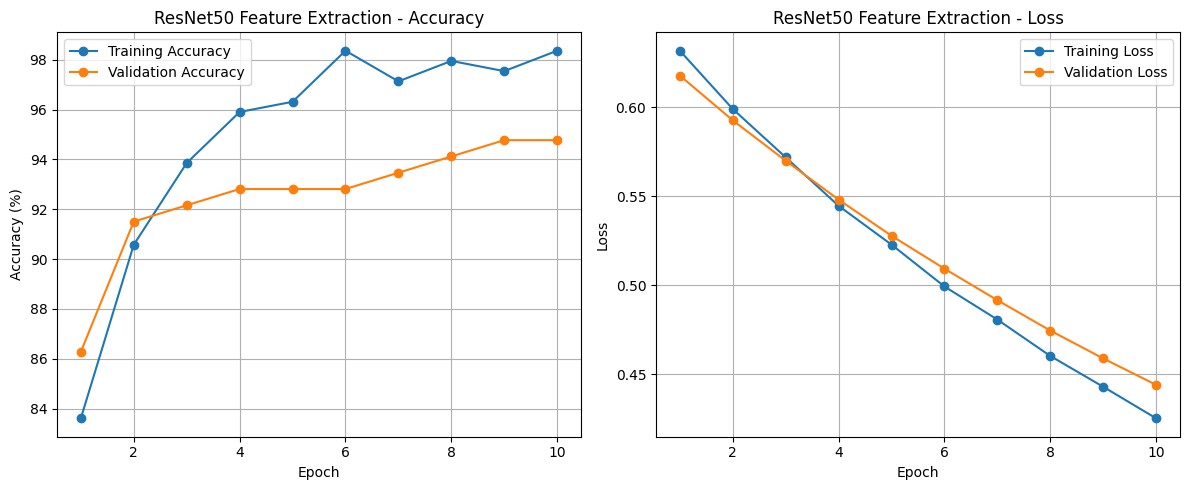

In [30]:
epochs_range = range(
    1,
    len(resnet_fe_history["train_acc"]) + 1
)

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    resnet_fe_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    resnet_fe_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("ResNet50 Feature Extraction - Accuracy")
plt.legend()
plt.grid()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    resnet_fe_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    resnet_fe_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Feature Extraction - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [31]:
def best_checkpoint_results(history):
    best_idx = min(
        range(len(history["val_loss"])),
        key=lambda i: history["val_loss"][i]
    )

    return {
        "epoch": best_idx + 1,
        "accuracy": history["val_acc"][best_idx],
        "loss": history["val_loss"][best_idx]
    }


ft_result = best_checkpoint_results(resnet_ft_history)
fe_result = best_checkpoint_results(resnet_fe_history)

print("ResNet50 Fine-Tuning")
print("Best Epoch:", ft_result["epoch"])
print("Validation Accuracy:", round(ft_result["accuracy"], 2), "%")
print("Validation Loss:", round(ft_result["loss"], 4))

print("\nResNet50 Feature Extraction")
print("Best Epoch:", fe_result["epoch"])
print("Validation Accuracy:", round(fe_result["accuracy"], 2), "%")
print("Validation Loss:", round(fe_result["loss"], 4))

ResNet50 Fine-Tuning
Best Epoch: 6
Validation Accuracy: 96.08 %
Validation Loss: 0.0988

ResNet50 Feature Extraction
Best Epoch: 10
Validation Accuracy: 94.77 %
Validation Loss: 0.4439


## Experiment 3: ResNet50 Feature Extraction — Results and Analysis

In this experiment, pretrained ResNet50 was used as a fixed feature extractor. All pretrained backbone parameters were frozen, and only the new two-class classification layer was trained on the Hymenoptera dataset.

### Results

| Metric | Feature Extraction | Fine-Tuning |
|---|---:|---:|
| Best Checkpoint Epoch | 10 | 6 |
| Validation Accuracy | 94.77% | 96.08% |
| Validation Loss | 0.4439 | 0.0988 |
| Training Time | 35.14 s | 35.44 s |
| Trainable Parameters | 4,098 | 14,968,834 |

### Observations

The feature-extraction model showed consistent improvement throughout training. Training accuracy increased from 83.61% to 98.36%, while validation accuracy increased from 86.27% to 94.77%.

Both training and validation losses decreased throughout the ten epochs, indicating that the newly added classifier successfully learned to distinguish ants and bees using the pretrained features.

The model showed a small training-validation accuracy gap, but validation loss continued decreasing, so there was no clear evidence of severe overfitting.

Compared with feature extraction, ResNet50 fine-tuning achieved higher validation accuracy and substantially lower validation loss.

This suggests that allowing the final residual block to update helped the pretrained model adapt its features to the new classification task.

### Conclusion

Both feature extraction and fine-tuning performed well on the Hymenoptera dataset.

However, **ResNet50 fine-tuning achieved better validation performance**, reaching 96.08% accuracy and 0.0988 loss compared with 94.77% accuracy and 0.4439 loss for feature extraction.

Therefore, fine-tuning provided an advantage in this experiment, although it required updating substantially more parameters.

In [32]:
import os

save_dir = "/content/tutorial7_checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "fc_state_dict": resnet50_fe.fc.state_dict(),
    "history": resnet_fe_history,
    "training_time": resnet_fe_time
}, os.path.join(save_dir, "resnet50_feature_extraction.pth"))

print("ResNet50 Feature Extraction checkpoint saved.")

ResNet50 Feature Extraction checkpoint saved.


# Experiment 4 — VGG16 Fine-Tuning

In this experiment, pretrained VGG16 is fine-tuned by unfreezing its final convolutional block while keeping the earlier convolutional layers frozen.

A new two-class classifier is trained together with the final convolutional block to classify ants and bees.

The results will be compared with VGG16 feature extraction to evaluate the effect of fine-tuning.

In [33]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.models import VGG16_Weights

# Load fresh pretrained VGG16
vgg16_ft = models.vgg16(
    weights=VGG16_Weights.DEFAULT
)

# Freeze all pretrained parameters
for param in vgg16_ft.parameters():
    param.requires_grad = False

# Unfreeze the final convolutional block
# In torchvision VGG16, this block is features[24:31]
for param in vgg16_ft.features[24:31].parameters():
    param.requires_grad = True

# Replace original classifier
vgg16_ft.classifier = nn.Sequential(
    nn.Linear(512 * 7 * 7, 64),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(64, 2)
)

vgg16_ft = vgg16_ft.to(device)

print("VGG16 Fine-Tuning Model Ready")
print(vgg16_ft.classifier)

VGG16 Fine-Tuning Model Ready
Sequential(
  (0): Linear(in_features=25088, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=64, out_features=2, bias=True)
)


In [34]:
total_params = sum(
    p.numel() for p in vgg16_ft.parameters()
)

trainable_params = sum(
    p.numel()
    for p in vgg16_ft.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)
print("Frozen Parameters:", total_params - trainable_params)

Total Parameters: 16320514
Trainable Parameters: 8685250
Frozen Parameters: 7635264


In [35]:
criterion_vgg_ft = nn.CrossEntropyLoss()

optimizer_vgg_ft = optim.Adam([
    {
        "params": vgg16_ft.features[24:31].parameters(),
        "lr": 0.00001
    },
    {
        "params": vgg16_ft.classifier.parameters(),
        "lr": 0.0001
    }
], weight_decay=0.001)

print("Optimizer Ready")

Optimizer Ready


In [36]:
vgg16_ft, vgg_ft_history, vgg_ft_time = train_model(
    model=vgg16_ft,
    dataloaders=dataloaders,
    criterion=criterion_vgg_ft,
    optimizer=optimizer_vgg_ft,
    num_epochs=10,
    patience=3
)


Epoch 1/10
TRAIN | Loss: 0.4779 | Accuracy: 76.64%
VAL | Loss: 0.2788 | Accuracy: 90.20%

Epoch 2/10
TRAIN | Loss: 0.1904 | Accuracy: 92.62%
VAL | Loss: 0.2409 | Accuracy: 92.81%

Epoch 3/10
TRAIN | Loss: 0.0893 | Accuracy: 97.54%
VAL | Loss: 0.2446 | Accuracy: 92.16%

Epoch 4/10
TRAIN | Loss: 0.0556 | Accuracy: 98.36%
VAL | Loss: 0.2252 | Accuracy: 94.12%

Epoch 5/10
TRAIN | Loss: 0.0233 | Accuracy: 99.59%
VAL | Loss: 0.2495 | Accuracy: 93.46%

Epoch 6/10
TRAIN | Loss: 0.0167 | Accuracy: 100.00%
VAL | Loss: 0.2468 | Accuracy: 94.12%

Epoch 7/10
TRAIN | Loss: 0.0206 | Accuracy: 98.77%
VAL | Loss: 0.2551 | Accuracy: 95.42%

Early Stopping triggered.

Training completed.
Best Epoch: 4
Validation Accuracy at Best Epoch: 94.12 %
Best Validation Loss: 0.2252
Training Time: 30.88 seconds


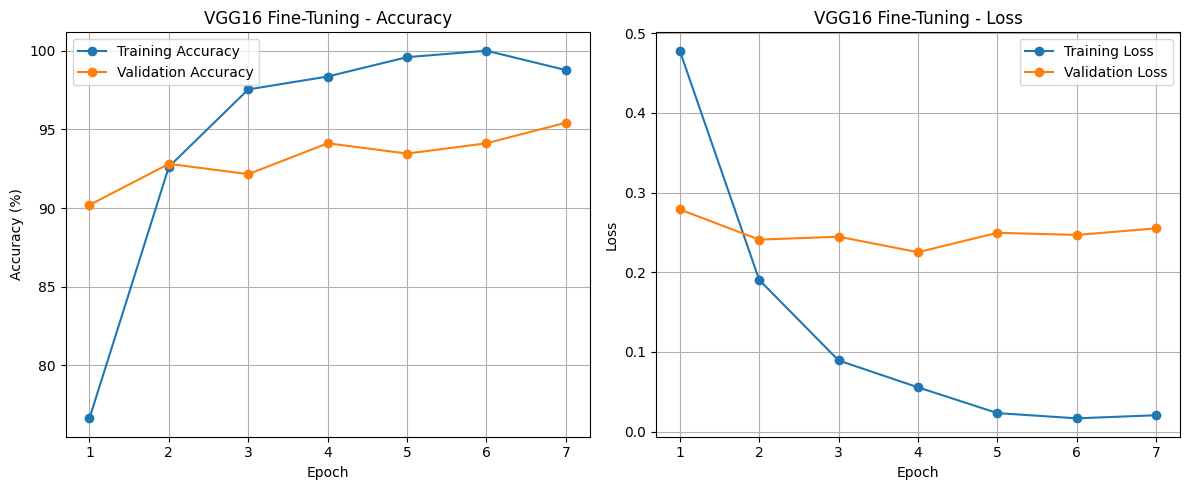

In [37]:
epochs_range = range(
    1,
    len(vgg_ft_history["train_acc"]) + 1
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    vgg_ft_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    vgg_ft_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("VGG16 Fine-Tuning - Accuracy")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    vgg_ft_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    vgg_ft_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VGG16 Fine-Tuning - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [38]:
vgg_fe_result = best_checkpoint_results(
    vgg_improved_history
)

vgg_ft_result = best_checkpoint_results(
    vgg_ft_history
)

print("VGG16 Feature Extraction")
print("Best Epoch:", vgg_fe_result["epoch"])
print(
    "Validation Accuracy:",
    round(vgg_fe_result["accuracy"], 2), "%"
)
print(
    "Validation Loss:",
    round(vgg_fe_result["loss"], 4)
)

print("\nVGG16 Fine-Tuning")
print("Best Epoch:", vgg_ft_result["epoch"])
print(
    "Validation Accuracy:",
    round(vgg_ft_result["accuracy"], 2), "%"
)
print(
    "Validation Loss:",
    round(vgg_ft_result["loss"], 4)
)

VGG16 Feature Extraction
Best Epoch: 3
Validation Accuracy: 94.77 %
Validation Loss: 0.2206

VGG16 Fine-Tuning
Best Epoch: 4
Validation Accuracy: 94.12 %
Validation Loss: 0.2252


## Experiment 4: VGG16 Fine-Tuning — Results and Analysis

In this experiment, pretrained VGG16 was fine-tuned by unfreezing its final convolutional block while keeping the earlier pretrained layers frozen.

The new two-class classifier was trained together with the final convolutional block. Different learning rates were used for the pretrained layers (`0.00001`) and the classifier (`0.0001`), with weight decay applied for regularization.

### Results

| Metric | Feature Extraction | Fine-Tuning |
|---|---:|---:|
| Best Checkpoint Epoch | 3 | 4 |
| Validation Accuracy | 94.77% | 94.12% |
| Validation Loss | 0.2206 | 0.2252 |
| Training Time | 25.17 s | 30.88 s |

### Observations

The fine-tuned VGG16 model learned rapidly, with training accuracy reaching 100% by epoch 6. However, validation accuracy remained approximately 92–95%, while validation loss stopped improving consistently after epoch 4.

This indicates mild overfitting, as the model continued improving on the training images without achieving consistent improvements on unseen validation images.

Early Stopping was triggered after epoch 7, restoring the weights from epoch 4, which had the lowest validation loss.

Compared with the feature-extraction model, fine-tuning achieved slightly lower validation accuracy and slightly higher validation loss at the selected checkpoints.

This may be due to the small dataset size, where unfreezing additional pretrained parameters increases model capacity without necessarily improving generalization.



In [39]:
import os

save_dir = "/content/tutorial7_checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "features_block5_state_dict":
        vgg16_ft.features[24:31].state_dict(),

    "classifier_state_dict":
        vgg16_ft.classifier.state_dict(),

    "history": vgg_ft_history,
    "training_time": vgg_ft_time
}, os.path.join(save_dir, "vgg16_finetuning.pth"))

print("VGG16 fine-tuning checkpoint saved.")

VGG16 fine-tuning checkpoint saved.


# Experiment 5 — Custom CNN (Training from Scratch)

In this experiment, a custom Convolutional Neural Network is developed using PyTorch without pretrained weights.

The model is trained on the Hymenoptera dataset to classify ants and bees.

Its performance will be compared with pretrained VGG16 and ResNet50 models to investigate the benefits of transfer learning.

In [40]:
import torch
import torch.nn as nn
import torch.optim as optim

class CustomCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            # Convolution Block 1
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Convolution Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Convolution Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),

            # Reduce feature map to 1 x 1
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(32, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


custom_model = CustomCNN().to(device)

print(custom_model)

CustomCNN(
  (features): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(1, 1))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=64, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=32, out_features=2, bias=True)
  )
)


In [41]:
total_params = sum(
    p.numel() for p in custom_model.parameters()
)

trainable_params = sum(
    p.numel()
    for p in custom_model.parameters()
    if p.requires_grad
)

print("Total Parameters:", total_params)
print("Trainable Parameters:", trainable_params)

Total Parameters: 25730
Trainable Parameters: 25730


In [42]:
criterion_custom = nn.CrossEntropyLoss()

optimizer_custom = optim.Adam(
    custom_model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

print("Optimizer Ready")

Optimizer Ready


In [43]:
custom_model, custom_history, custom_time = train_model(
    model=custom_model,
    dataloaders=dataloaders,
    criterion=criterion_custom,
    optimizer=optimizer_custom,
    num_epochs=20,
    patience=5
)


Epoch 1/20
TRAIN | Loss: 0.6954 | Accuracy: 50.00%
VAL | Loss: 0.6892 | Accuracy: 51.63%

Epoch 2/20
TRAIN | Loss: 0.6693 | Accuracy: 56.97%
VAL | Loss: 0.6753 | Accuracy: 57.52%

Epoch 3/20
TRAIN | Loss: 0.6564 | Accuracy: 58.61%
VAL | Loss: 0.7089 | Accuracy: 52.94%

Epoch 4/20
TRAIN | Loss: 0.6500 | Accuracy: 59.84%
VAL | Loss: 0.6647 | Accuracy: 59.48%

Epoch 5/20
TRAIN | Loss: 0.6277 | Accuracy: 61.89%
VAL | Loss: 0.6855 | Accuracy: 54.90%

Epoch 6/20
TRAIN | Loss: 0.6104 | Accuracy: 65.98%
VAL | Loss: 0.6438 | Accuracy: 60.13%

Epoch 7/20
TRAIN | Loss: 0.6152 | Accuracy: 65.16%
VAL | Loss: 0.6723 | Accuracy: 58.82%

Epoch 8/20
TRAIN | Loss: 0.6267 | Accuracy: 65.16%
VAL | Loss: 0.6332 | Accuracy: 60.78%

Epoch 9/20
TRAIN | Loss: 0.6074 | Accuracy: 68.44%
VAL | Loss: 0.6197 | Accuracy: 66.67%

Epoch 10/20
TRAIN | Loss: 0.5778 | Accuracy: 69.26%
VAL | Loss: 0.6212 | Accuracy: 65.36%

Epoch 11/20
TRAIN | Loss: 0.5823 | Accuracy: 70.08%
VAL | Loss: 0.6253 | Accuracy: 64.71%

Epoch 1

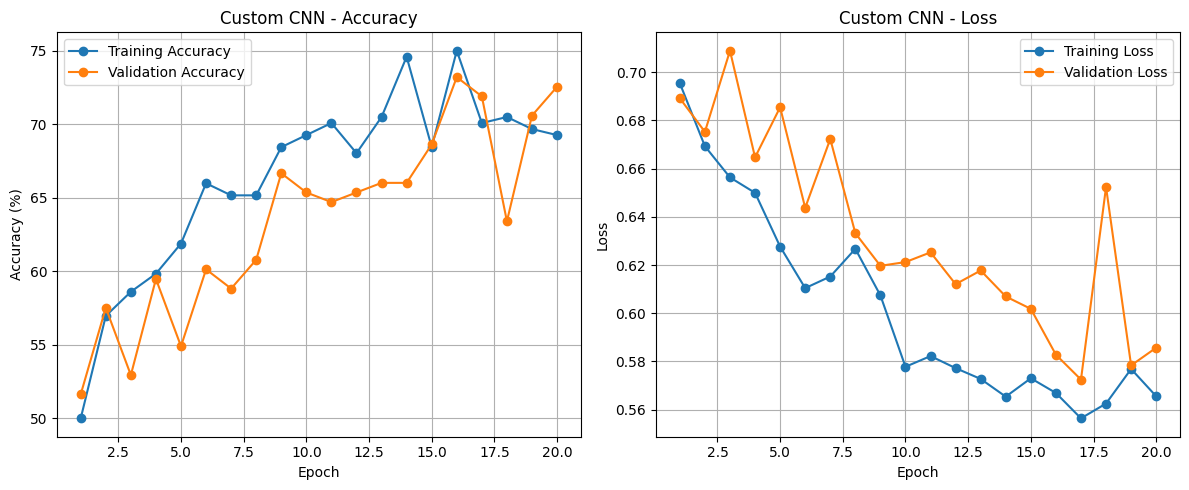

In [44]:
epochs_range = range(
    1,
    len(custom_history["train_acc"]) + 1
)

plt.figure(figsize=(12, 5))

# Accuracy graph
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    custom_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    custom_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Custom CNN - Accuracy")
plt.legend()
plt.grid()

# Loss graph
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    custom_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    custom_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Custom CNN - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [45]:
def best_checkpoint_results(history):

    best_idx = min(
        range(len(history["val_loss"])),
        key=lambda i: history["val_loss"][i]
    )

    return {
        "epoch": best_idx + 1,
        "accuracy": history["val_acc"][best_idx],
        "loss": history["val_loss"][best_idx]
    }


results = {
    "VGG16 Feature Extraction": best_checkpoint_results(
        vgg_improved_history
    ),

    "ResNet50 Feature Extraction": best_checkpoint_results(
        resnet_fe_history
    ),

    "ResNet50 Fine-Tuning": best_checkpoint_results(
        resnet_ft_history
    ),

    "VGG16 Fine-Tuning": best_checkpoint_results(
        vgg_ft_history
    ),

    "Custom CNN": best_checkpoint_results(
        custom_history
    )
}

for name, result in results.items():

    print(name)
    print("Best Epoch:", result["epoch"])
    print("Validation Accuracy:", round(result["accuracy"], 2), "%")
    print("Validation Loss:", round(result["loss"], 4))
    print("-----------------------------")

VGG16 Feature Extraction
Best Epoch: 3
Validation Accuracy: 94.77 %
Validation Loss: 0.2206
-----------------------------
ResNet50 Feature Extraction
Best Epoch: 10
Validation Accuracy: 94.77 %
Validation Loss: 0.4439
-----------------------------
ResNet50 Fine-Tuning
Best Epoch: 6
Validation Accuracy: 96.08 %
Validation Loss: 0.0988
-----------------------------
VGG16 Fine-Tuning
Best Epoch: 4
Validation Accuracy: 94.12 %
Validation Loss: 0.2252
-----------------------------
Custom CNN
Best Epoch: 17
Validation Accuracy: 71.9 %
Validation Loss: 0.5725
-----------------------------


In [45]:
import os

save_dir = "/content/tutorial7_checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "model_state_dict": custom_model.state_dict(),
    "history": custom_history,
    "training_time": custom_time
}, os.path.join(save_dir, "custom_cnn.pth"))

print("Custom CNN checkpoint saved.")

## Experiment 5: Custom CNN — Results and Analysis

A custom Convolutional Neural Network was implemented using PyTorch and trained from scratch on the Hymenoptera dataset.

Unlike VGG16 and ResNet50, this model did not use pretrained ImageNet weights. All 25,730 parameters were initialized and trained using the available 244 training images.

### Results

| Metric | Result |
|---|---:|
| Total Trainable Parameters | 25,730 |
| Epochs Completed | 20 |
| Best Checkpoint Epoch | 17 |
| Validation Accuracy | 71.90% |
| Validation Loss | 0.5725 |
| Training Time | 55.92 seconds |

### Observations

Training and validation accuracy generally improved over the training period but showed noticeable fluctuations.

The model achieved 71.90% validation accuracy at the checkpoint with the lowest validation loss.

Training and validation accuracy remained relatively close, indicating that severe overfitting was not the primary problem.

However, both accuracies remained significantly lower than those of the pretrained models, suggesting that the custom CNN had not learned sufficiently effective image features.

One possible reason is the small training dataset. With only 244 images, a CNN trained from scratch has limited examples from which to learn visual patterns.

### Comparison with Pretrained Models

| Model | Validation Accuracy |
|---|---:|
| VGG16 Feature Extraction | 94.77% |
| ResNet50 Feature Extraction | 94.77% |
| ResNet50 Fine-Tuning | 96.08% |
| VGG16 Fine-Tuning | 94.12% |
| Custom CNN | 71.90% |

All pretrained models achieved substantially higher validation accuracy than the custom CNN.

This demonstrates the advantage of transfer learning when the available dataset is small.

### Conclusion

The custom CNN achieved **71.90% validation accuracy**, compared with **94.77% for ResNet50 feature extraction** and **96.08% for ResNet50 fine-tuning**.

The experiment shows that pretrained feature representations can significantly improve classification performance when training data is limited.

The custom CNN did not show severe overfitting, but its relatively low accuracy suggests underfitting or insufficient feature learning.

# Experiment 6 — Improving ResNet50 Fine-Tuning

In this experiment, the ResNet50 fine-tuning configuration is modified to investigate whether stronger regularization, smaller learning rates, and a longer training period improve generalization.

The results will be compared with the original ResNet50 fine-tuning model.

In [46]:
import torch
import torch.nn as nn
import torch.optim as optim

from torchvision import models
from torchvision.models import ResNet50_Weights

# Load fresh pretrained ResNet50
resnet50_improved = models.resnet50(
    weights=ResNet50_Weights.DEFAULT
)

# Freeze all pretrained parameters
for param in resnet50_improved.parameters():
    param.requires_grad = False

# Unfreeze final residual block
for param in resnet50_improved.layer4.parameters():
    param.requires_grad = True

# New classifier with Dropout
resnet50_improved.fc = nn.Sequential(
    nn.Dropout(p=0.5),
    nn.Linear(2048, 2)
)

resnet50_improved = resnet50_improved.to(device)

print("Improved ResNet50 model ready.")
print(resnet50_improved.fc)

Improved ResNet50 model ready.
Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Linear(in_features=2048, out_features=2, bias=True)
)


In [47]:
criterion_resnet_improved = nn.CrossEntropyLoss()

optimizer_resnet_improved = optim.Adam([
    {
        "params": resnet50_improved.layer4.parameters(),
        "lr": 0.000005
    },
    {
        "params": resnet50_improved.fc.parameters(),
        "lr": 0.00005
    }
], weight_decay=0.001)

print("Improved optimizer ready.")

Improved optimizer ready.


In [48]:
resnet50_improved, improved_history, improved_time = train_model(
    model=resnet50_improved,
    dataloaders=dataloaders,
    criterion=criterion_resnet_improved,
    optimizer=optimizer_resnet_improved,
    num_epochs=15,
    patience=4
)


Epoch 1/15
TRAIN | Loss: 0.6221 | Accuracy: 79.51%
VAL | Loss: 0.6122 | Accuracy: 89.54%

Epoch 2/15
TRAIN | Loss: 0.5730 | Accuracy: 88.52%
VAL | Loss: 0.5791 | Accuracy: 92.81%

Epoch 3/15
TRAIN | Loss: 0.5421 | Accuracy: 91.39%
VAL | Loss: 0.5383 | Accuracy: 94.12%

Epoch 4/15
TRAIN | Loss: 0.4812 | Accuracy: 95.08%
VAL | Loss: 0.4834 | Accuracy: 93.46%

Epoch 5/15
TRAIN | Loss: 0.4028 | Accuracy: 96.31%
VAL | Loss: 0.4151 | Accuracy: 92.16%

Epoch 6/15
TRAIN | Loss: 0.3109 | Accuracy: 95.49%
VAL | Loss: 0.3209 | Accuracy: 92.81%

Epoch 7/15
TRAIN | Loss: 0.2059 | Accuracy: 98.77%
VAL | Loss: 0.2314 | Accuracy: 94.12%

Epoch 8/15
TRAIN | Loss: 0.1122 | Accuracy: 99.59%
VAL | Loss: 0.1569 | Accuracy: 95.42%

Epoch 9/15
TRAIN | Loss: 0.0606 | Accuracy: 99.18%
VAL | Loss: 0.1187 | Accuracy: 96.08%

Epoch 10/15
TRAIN | Loss: 0.0314 | Accuracy: 99.59%
VAL | Loss: 0.1028 | Accuracy: 96.73%

Epoch 11/15
TRAIN | Loss: 0.0234 | Accuracy: 99.59%
VAL | Loss: 0.1281 | Accuracy: 95.42%

Epoch 1

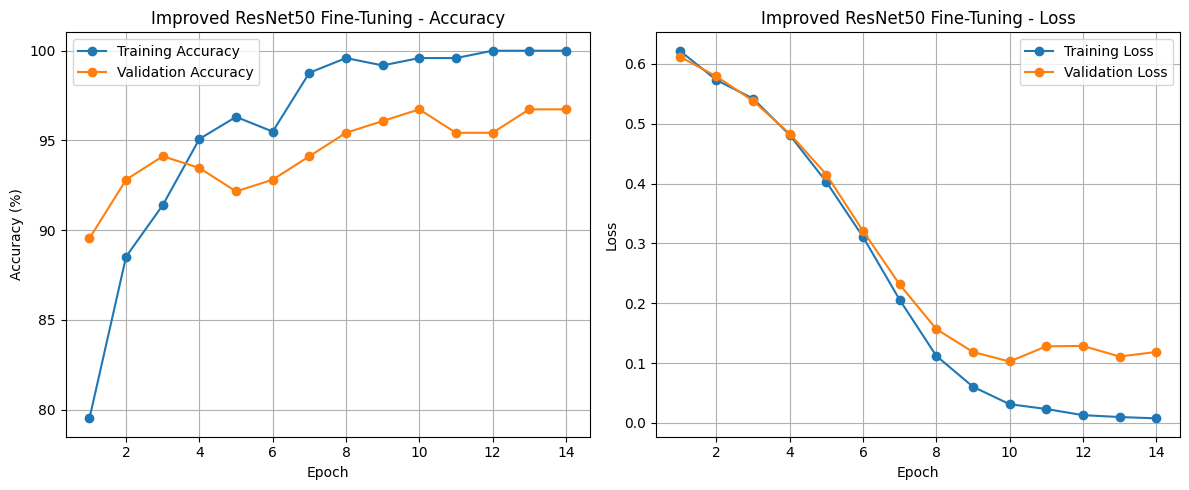

In [49]:
epochs_range = range(
    1,
    len(improved_history["train_acc"]) + 1
)

plt.figure(figsize=(12, 5))

# Accuracy
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    improved_history["train_acc"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    improved_history["val_acc"],
    marker="o",
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Improved ResNet50 Fine-Tuning - Accuracy")
plt.legend()
plt.grid()

# Loss
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    improved_history["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    epochs_range,
    improved_history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Improved ResNet50 Fine-Tuning - Loss")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [50]:
original_result = best_checkpoint_results(
    resnet_ft_history
)

improved_result = best_checkpoint_results(
    improved_history
)

print("Original ResNet50 Fine-Tuning")
print("Best Epoch:", original_result["epoch"])
print("Validation Accuracy:",
      round(original_result["accuracy"], 2), "%")
print("Validation Loss:",
      round(original_result["loss"], 4))

print("\nImproved ResNet50 Fine-Tuning")
print("Best Epoch:", improved_result["epoch"])
print("Validation Accuracy:",
      round(improved_result["accuracy"], 2), "%")
print("Validation Loss:",
      round(improved_result["loss"], 4))

print("\nTraining Time Comparison")
print("Original:", round(resnet_ft_time, 2), "seconds")
print("Improved:", round(improved_time, 2), "seconds")

Original ResNet50 Fine-Tuning
Best Epoch: 6
Validation Accuracy: 96.08 %
Validation Loss: 0.0988

Improved ResNet50 Fine-Tuning
Best Epoch: 10
Validation Accuracy: 96.73 %
Validation Loss: 0.1028

Training Time Comparison
Original: 35.44 seconds
Improved: 53.75 seconds


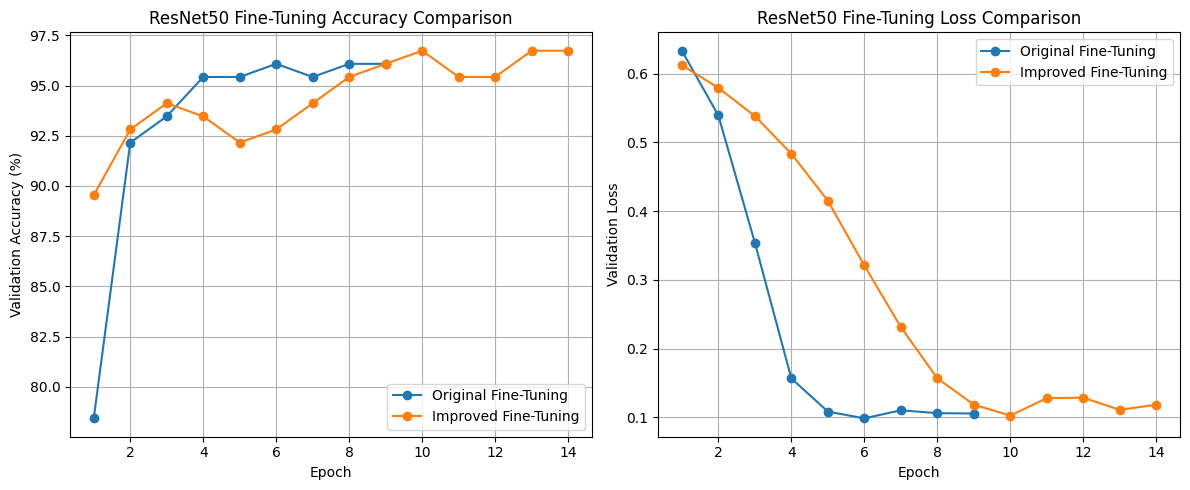

In [51]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)

plt.plot(
    range(1, len(resnet_ft_history["val_acc"]) + 1),
    resnet_ft_history["val_acc"],
    marker="o",
    label="Original Fine-Tuning"
)

plt.plot(
    range(1, len(improved_history["val_acc"]) + 1),
    improved_history["val_acc"],
    marker="o",
    label="Improved Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Accuracy (%)")
plt.title("ResNet50 Fine-Tuning Accuracy Comparison")
plt.legend()
plt.grid()

plt.subplot(1, 2, 2)

plt.plot(
    range(1, len(resnet_ft_history["val_loss"]) + 1),
    resnet_ft_history["val_loss"],
    marker="o",
    label="Original Fine-Tuning"
)

plt.plot(
    range(1, len(improved_history["val_loss"]) + 1),
    improved_history["val_loss"],
    marker="o",
    label="Improved Fine-Tuning"
)

plt.xlabel("Epoch")
plt.ylabel("Validation Loss")
plt.title("ResNet50 Fine-Tuning Loss Comparison")
plt.legend()
plt.grid()

plt.tight_layout()
plt.show()

In [52]:
from google.colab import drive
import os

drive.mount("/content/drive")

save_dir = "/content/drive/MyDrive/Tutorial7_Checkpoints"
os.makedirs(save_dir, exist_ok=True)

torch.save({
    "layer4_state_dict": resnet50_improved.layer4.state_dict(),
    "fc_state_dict": resnet50_improved.fc.state_dict(),
    "history": improved_history,
    "training_time": improved_time
}, os.path.join(save_dir, "resnet50_improved_finetuning.pth"))

print("Improved model saved to Google Drive.")

Mounted at /content/drive
Improved model saved to Google Drive.


## Experiment 6: Improving ResNet50 Fine-Tuning — Results and Analysis

The original ResNet50 fine-tuning model was modified to investigate whether smaller learning rates, stronger regularization, Dropout, and a longer training period could improve classification performance.

The modified model used a backbone learning rate of `0.000005`, a classifier learning rate of `0.00005`, weight decay of `0.001`, Dropout of `0.5`, and Early Stopping with a patience of four epochs.

### Results

| Metric | Original Fine-Tuning | Improved Fine-Tuning |
|---|---:|---:|
| Best Checkpoint Epoch | 6 | 10 |
| Validation Accuracy | 96.08% | 96.73% |
| Validation Loss | 0.0988 | 0.1028 |
| Training Time | 35.44 s | 53.75 s |
| Epochs Completed | 9 | 14 |

### Observations

The improved model achieved a slightly higher validation accuracy of 96.73%, compared with 96.08% for the original fine-tuning model.

However, validation loss increased slightly from 0.0988 to 0.1028, indicating that the improved configuration did not outperform the original model on every evaluation metric.

The improved model also required more training time because of its longer training period.

Training accuracy approached 100%, while validation accuracy remained around 96–97%. After epoch 10, validation loss stopped improving and began increasing, indicating mild overfitting.

Early Stopping was triggered after epoch 14 and restored the weights from epoch 10, which had the lowest validation loss.

### Conclusion

The modified ResNet50 fine-tuning configuration achieved **96.73% validation accuracy**, improving upon the original model's 96.08%.

However, the original model retained a slightly lower validation loss and required less training time.

Therefore, the improved configuration provided a small gain in classification accuracy but did not improve all aspects of model performance.

The experiment demonstrates that fine-tuning performance depends on learning rate, regularization, and training duration, and that a more strongly regularized model does not necessarily outperform the original configuration in every metric.

# Final Conclusion — Tutorial 7

In this tutorial, feature extraction and fine-tuning were implemented and compared using PyTorch on the Hymenoptera dataset for ants-versus-bees classification.

Pretrained VGG16 and ResNet50 models were evaluated using both feature extraction and fine-tuning approaches. A custom CNN trained from scratch was also implemented to investigate the benefits of transfer learning.

### Key Findings

- **Feature Extraction:** Both VGG16 and ResNet50 achieved strong classification performance while keeping their pretrained backbones frozen.
- **Fine-Tuning:** ResNet50 fine-tuning improved validation accuracy compared with ResNet50 feature extraction, demonstrating the benefit of adapting pretrained features to the target dataset.
- **VGG16 Fine-Tuning:** Fine-tuning did not outperform VGG16 feature extraction at the selected checkpoints, showing that unfreezing additional layers does not always improve generalization.
- **Custom CNN:** The model trained from scratch achieved substantially lower validation accuracy, highlighting the advantage of pretrained representations when training data is limited.
- **Fine-Tuning Improvements:** Adjusting learning rates, adding Dropout and weight decay, and applying Early Stopping improved ResNet50 validation accuracy slightly, although validation loss and training time did not improve.

### Best Results

The highest validation accuracy was achieved by the improved ResNet50 fine-tuning model at **96.73%**.

The lowest validation loss was achieved by the original ResNet50 fine-tuning model at **0.0988**.

### Overall Conclusion

The experiments demonstrate that transfer learning is highly effective for small image-classification datasets.

Feature extraction provides a computationally simpler approach by training only the classification head, while fine-tuning can improve performance by allowing selected pretrained layers to adapt to the target task.

However, fine-tuning increases model complexity and may introduce overfitting. Careful selection of learning rates, regularization, and Early Stopping is important for maintaining good generalization.

Overall, ResNet50 fine-tuning provided the strongest validation performance in these experiments, while the custom CNN trained from scratch performed substantially worse.